# Notebook 03b — Model Design: Advanced ML (XGBoost)

**Proyek:** Termal-Guard — Prediksi Level Risiko Stres Panas Satu Hari ke Depan  
**Notebook:** `03_model_design_advanced_ml.ipynb`  
**Model:** XGBoost Classifier (Model 2 — Advanced ML)  
**LKM:** Minggu 3 — [M] Model Design: Baseline & Advanced  

---

## Tujuan Notebook

Notebook ini melatih **Model 2 (Advanced ML)** menggunakan **XGBoost Classifier** dan mengevaluasinya  
pada **Validation Set** (2025). Hasil dibandingkan dengan Model 1 (Baseline Decision Tree)  
dari `03_model_design_baseline_ml.ipynb`.

**Metrik Utama:** Macro F1-Score dan Recall pada kelas `High (2)` & `Extreme (3)`  
karena *false negative* pada kelas risiko tinggi berpotensi menyebabkan *heat stroke*.

> ⚠️ **PERINGATAN:** Notebook ini HANYA menggunakan `X_val.csv` / `y_val.csv` untuk evaluasi.  
> `X_test.csv` / `y_test.csv` **dilarang keras** diakses pada LKM 12 ini.

## 1. Setup & Load Data

In [1]:
import json
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
)
from xgboost import XGBClassifier

# Path relatif yang aman (sama seperti notebook baseline)
PROCESSED_DIR = Path("../data/processed")
if not PROCESSED_DIR.exists():
    PROCESSED_DIR = Path("data/processed")

# Load Dataset Train & Validation
X_train = pd.read_csv(PROCESSED_DIR / "X_train.csv")
y_train = pd.read_csv(PROCESSED_DIR / "y_train.csv").values.ravel()

X_val = pd.read_csv(PROCESSED_DIR / "X_val.csv")
y_val = pd.read_csv(PROCESSED_DIR / "y_val.csv").values.ravel()

# Load Class Weights JSON
with open(PROCESSED_DIR / "class_weights.json", "r") as f:
    class_weights_raw = json.load(f)

# Mapping Kunci JSON ke Integer (0, 1, 2, 3)
label_mapping = {"Low": 0, "Moderate": 1, "High": 2, "Extreme": 3}
class_weights = {}
for k, v in class_weights_raw.items():
    if k in label_mapping:
        class_weights[label_mapping[k]] = float(v)
    else:
        class_weights[int(k)] = float(v)

# Verifikasi data
print(f"Data Training   : {X_train.shape[0]} sampel, {X_train.shape[1]} fitur")
print(f"Data Validation : {X_val.shape[0]} sampel, {X_val.shape[1]} fitur")
print(f"Class Weights   : {class_weights}")
print(f"NaN Training    : {X_train.isnull().sum().sum()}")
print(f"NaN Validation  : {X_val.isnull().sum().sum()}")
print(f"\nFitur tersedia  : {list(X_train.columns)}")

Data Training   : 10206 sampel, 32 fitur
Data Validation : 2555 sampel, 32 fitur
Class Weights   : {0: 4.361538461538461, 1: 0.7906724511930586, 2: 0.4879518072289157, 3: 2.190128755364807}
NaN Training    : 0
NaN Validation  : 0

Fitur tersedia  : ['radiation_sum', 'temp_max', 'apparent_temp_max', 'wind_speed_max', 'precip_sum', 'latitude', 'longitude', 'elevation', 'oni_anom_lag1m', 'oni_anom_lag2m', 'oni_anom_lag3m', 'temp_max_lag1d', 'apparent_temp_lag1d', 'precip_lag1d', 'temp_max_lag2d', 'apparent_temp_lag2d', 'precip_lag2d', 'temp_max_lag3d', 'apparent_temp_lag3d', 'precip_lag3d', 'month', 'sin_doy', 'cos_doy', 'temp_range_or_heat_gap', 'apparent_temp_diff_1d', 'kota_Balikpapan', 'kota_Jakarta', 'kota_Jayapura', 'kota_Madiun', 'kota_Makasar', 'kota_Medan', 'kota_Surabaya']


## 2. Penanganan Class Imbalance untuk XGBoost

Berbeda dengan scikit-learn yang mendukung `class_weight` sebagai parameter, `XGBClassifier`  
untuk multikelas menggunakan **`sample_weight`** saat pemanggilan `.fit()`.  

Setiap sampel training diberikan bobot sesuai kelasnya:
- `Low (0)`: bobot tinggi (~4.36) → kelas minoritas paling kecil
- `Moderate (1)`: bobot rendah (~0.79) → kelas mayoritas
- `High (2)`: bobot terendah (~0.49) → kelas terbanyak  
- `Extreme (3)`: bobot sedang (~2.19) → kelas penting untuk safety

In [2]:
# Bangun array sample_weight_train
# Setiap label di y_train dipetakan ke bobot dari class_weights
sample_weight_train = np.array([class_weights[label] for label in y_train])

print("Sample Weight Statistics:")
print(f"  Total samples : {len(sample_weight_train)}")
print(f"  Min weight    : {sample_weight_train.min():.4f} (kelas High)")
print(f"  Max weight    : {sample_weight_train.max():.4f} (kelas Low)")
print(f"  Unique weights: {np.unique(sample_weight_train)}")

# Distribusi kelas training
unique, counts = np.unique(y_train, return_counts=True)
label_names = {0: 'Low', 1: 'Moderate', 2: 'High', 3: 'Extreme'}
print("\nDistribusi Kelas Training:")
for cls, cnt in zip(unique, counts):
    pct = cnt / len(y_train) * 100
    print(f"  Kelas {cls} ({label_names[cls]:>8}): {cnt:>5} sampel ({pct:.1f}%) — bobot: {class_weights[cls]:.4f}")

Sample Weight Statistics:
  Total samples : 10206
  Min weight    : 0.4880 (kelas High)
  Max weight    : 4.3615 (kelas Low)
  Unique weights: [0.48795181 0.79067245 2.19012876 4.36153846]

Distribusi Kelas Training:
  Kelas 0 (     Low):   585 sampel (5.7%) — bobot: 4.3615
  Kelas 1 (Moderate):  3227 sampel (31.6%) — bobot: 0.7907
  Kelas 2 (    High):  5229 sampel (51.2%) — bobot: 0.4880
  Kelas 3 ( Extreme):  1165 sampel (11.4%) — bobot: 2.1901


## 3. Training Model 2 — Advanced ML: XGBoost Classifier

### Parameter Awal XGBoost

Parameter berikut digunakan sebagai **konfigurasi awal** (*initial parameters*).  
Hyperparameter tuning mendalam akan dilengkapi pada **Minggu 4** sesuai timeline LKM.

| Parameter | Nilai | Alasan |
|-----------|-------|--------|
| `objective` | `multi:softprob` | Klasifikasi multikelas, output probabilitas |
| `num_class` | `4` | 4 level risiko: Low, Moderate, High, Extreme |
| `eval_metric` | `mlogloss` | Multi-class log loss untuk monitoring konvergensi |
| `n_estimators` | `200` | Jumlah pohon boosting; lebih banyak = lebih baik (hingga batas) |
| `max_depth` | `6` | Kedalaman maksimal pohon; membatasi kompleksitas |
| `learning_rate` | `0.1` | Step size shrinkage; nilai standar untuk awal |
| `subsample` | `0.8` | Fraksi sampel per iterasi; mencegah overfitting |
| `colsample_bytree` | `0.8` | Fraksi fitur per pohon; mencegah overfitting |
| `random_state` | `42` | Reproducibility |
| `n_jobs` | `-1` | Gunakan semua CPU cores |

In [3]:
# Inisialisasi XGBClassifier dengan parameter awal
xgb_model = XGBClassifier(
    objective="multi:softprob",
    num_class=4,
    eval_metric="mlogloss",
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
)

# Catat waktu training
start_train = time.time()
xgb_model.fit(
    X_train,
    y_train,
    sample_weight=sample_weight_train,
)
end_train = time.time()
train_duration = end_train - start_train

print(f"Status: Model Advanced XGBoost Berhasil Dilatih!")
print(f"Waktu Training : {train_duration:.4f} detik")

Status: Model Advanced XGBoost Berhasil Dilatih!
Waktu Training : 8.6164 detik


## 4. Evaluasi pada Validation Set

In [4]:
# Inferensi pada Validation Set
start_infer = time.time()
y_pred_val = xgb_model.predict(X_val)
end_infer = time.time()
infer_duration = end_infer - start_infer
latency_per_sample = (infer_duration / len(X_val)) * 1000

# Metrik pada Training Set (untuk deteksi overfitting)
y_pred_train = xgb_model.predict(X_train)
acc_train = accuracy_score(y_train, y_pred_train)
macro_f1_train = f1_score(y_train, y_pred_train, average="macro")

# Metrik pada Validation Set
acc_val = accuracy_score(y_val, y_pred_val)
macro_f1_val = f1_score(y_val, y_pred_val, average="macro")
weighted_f1_val = f1_score(y_val, y_pred_val, average="weighted")

# Per-kelas
precisions, recalls, f1s, supports = precision_recall_fscore_support(
    y_val, y_pred_val, labels=[0, 1, 2, 3]
)
recall_high = recalls[2]
recall_extreme = recalls[3]
recall_high_extreme_avg = (recalls[2] + recalls[3]) / 2

# Status overfitting
gap = abs(macro_f1_train - macro_f1_val)
if gap >= 0.20:
    status_overfit = "Mengalami Overfitting Parah"
elif gap >= 0.10:
    status_overfit = "Mengalami Overfitting Moderat"
else:
    status_overfit = "Model Stabil (Good Fit)"

# Tampilkan hasil lengkap
print("=" * 60)
print("ANALISIS LENGKAP MODEL ADVANCED — XGBoost")
print("=" * 60)
print(f"Validation Accuracy      : {acc_val:.4f} ({acc_val*100:.2f}%)")
print(f"Validation Macro F1      : {macro_f1_val:.4f}")
print(f"Validation Weighted F1   : {weighted_f1_val:.4f}")
print("-" * 60)
print(f"Training Macro F1        : {macro_f1_train:.4f} (Accuracy: {acc_train*100:.2f}%)")
print(f"Train-Val Gap (Overfit)  : {gap:.4f} ({status_overfit})")
print(f"Waktu Training           : {train_duration:.4f} detik")
print(f"Waktu Inferensi Total    : {infer_duration:.4f} detik ({latency_per_sample:.4f} ms/sample)")
print("-" * 60)
print(f"\n>>> METRIK KESELAMATAN PEKERJA <<<")
print(f"Recall kelas High (2)    : {recall_high:.4f} ({recall_high*100:.2f}%)")
print(f"Recall kelas Extreme (3) : {recall_extreme:.4f} ({recall_extreme*100:.2f}%)")
print(f"Avg Recall High+Extreme  : {recall_high_extreme_avg:.4f} ({recall_high_extreme_avg*100:.2f}%)")

target_names = [
    "Class 0 (Low)",
    "Class 1 (Moderate)",
    "Class 2 (High)",
    "Class 3 (Extreme)",
]
print("\nClassification Report (Validation Set 2025):\n")
print(classification_report(y_val, y_pred_val, target_names=target_names))

ANALISIS LENGKAP MODEL ADVANCED — XGBoost
Validation Accuracy      : 0.5476 (54.76%)
Validation Macro F1      : 0.4479
Validation Weighted F1   : 0.5527
------------------------------------------------------------
Training Macro F1        : 0.9093 (Accuracy: 90.55%)
Train-Val Gap (Overfit)  : 0.4614 (Mengalami Overfitting Parah)
Waktu Training           : 8.6164 detik
Waktu Inferensi Total    : 0.2566 detik (0.1004 ms/sample)
------------------------------------------------------------

>>> METRIK KESELAMATAN PEKERJA <<<
Recall kelas High (2)    : 0.6070 (60.70%)
Recall kelas Extreme (3) : 0.5361 (53.61%)
Avg Recall High+Extreme  : 0.5716 (57.16%)

Classification Report (Validation Set 2025):

                    precision    recall  f1-score   support

     Class 0 (Low)       0.26      0.23      0.24       117
Class 1 (Moderate)       0.48      0.49      0.48       750
    Class 2 (High)       0.67      0.61      0.64      1425
 Class 3 (Extreme)       0.36      0.54      0.43       

## 5. Visualisasi

### 5.1 Confusion Matrix (Validation Set)

Confusion Matrix saved: ..\reports\figures\cm_val_xgboost_initial.png


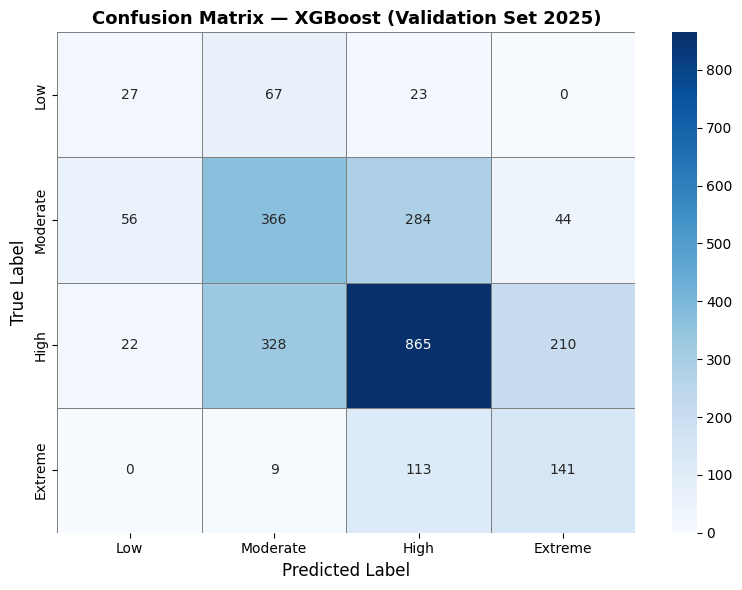

In [5]:
# Confusion Matrix
cm = confusion_matrix(y_val, y_pred_val)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low", "Moderate", "High", "Extreme"],
    yticklabels=["Low", "Moderate", "High", "Extreme"],
    ax=ax,
    linewidths=0.5,
    linecolor="gray",
)
ax.set_xlabel("Predicted Label", fontsize=12)
ax.set_ylabel("True Label", fontsize=12)
ax.set_title("Confusion Matrix — XGBoost (Validation Set 2025)", fontsize=13, fontweight="bold")
plt.tight_layout()

# Simpan ke reports/figures
fig_dir = Path("../reports/figures")
if not fig_dir.exists():
    fig_dir = Path("reports/figures")
fig_dir.mkdir(parents=True, exist_ok=True)
cm_path = fig_dir / "cm_val_xgboost_initial.png"
plt.savefig(str(cm_path), dpi=100, bbox_inches="tight")
print(f"Confusion Matrix saved: {cm_path}")
plt.show()

### 5.2 Top 15 Feature Importance

Feature Importance saved: ..\reports\figures\fi_xgboost_initial.png


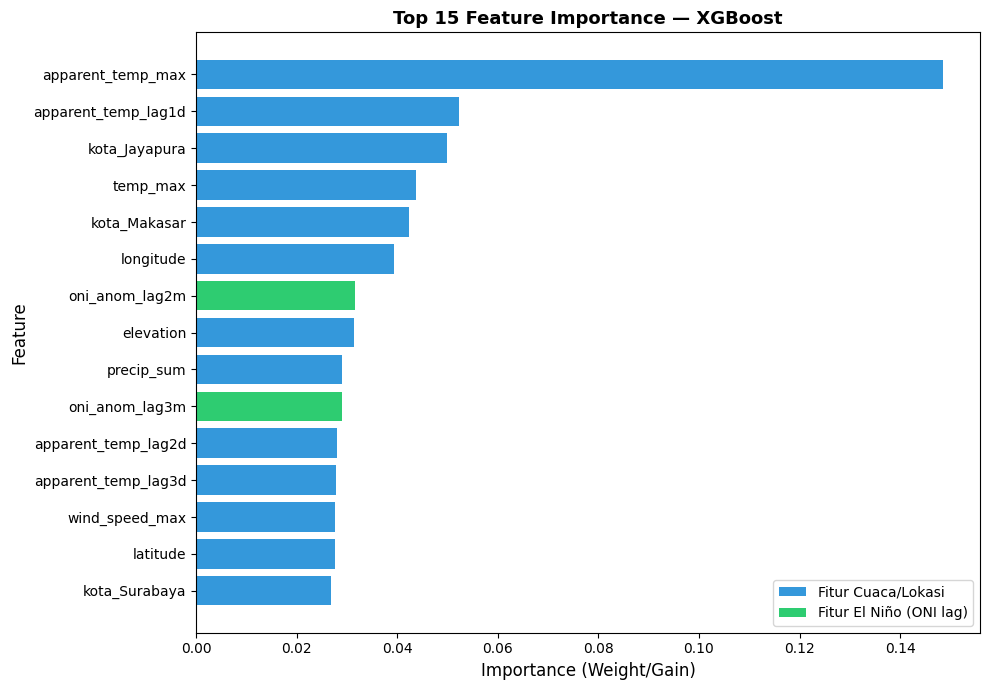


Top 15 Feature Importance:
            feature  importance
  apparent_temp_max    0.148451
apparent_temp_lag1d    0.052244
      kota_Jayapura    0.049876
           temp_max    0.043809
       kota_Makasar    0.042393
          longitude    0.039430
     oni_anom_lag2m    0.031596
          elevation    0.031349
         precip_sum    0.029096
     oni_anom_lag3m    0.028982
apparent_temp_lag2d    0.028083
apparent_temp_lag3d    0.027778
     wind_speed_max    0.027719
           latitude    0.027590
      kota_Surabaya    0.026814


In [6]:
# Feature Importance
importances = xgb_model.feature_importances_
feature_names = X_train.columns.tolist()
feat_imp_df = pd.DataFrame({"feature": feature_names, "importance": importances})
feat_imp_df = feat_imp_df.sort_values("importance", ascending=False).head(15)

fig2, ax2 = plt.subplots(figsize=(10, 7))
colors = ["#2ecc71" if "oni" in f else "#3498db" for f in feat_imp_df["feature"]]
bars = ax2.barh(feat_imp_df["feature"][::-1], feat_imp_df["importance"][::-1], color=colors[::-1])
ax2.set_xlabel("Importance (Weight/Gain)", fontsize=12)
ax2.set_ylabel("Feature", fontsize=12)
ax2.set_title("Top 15 Feature Importance — XGBoost", fontsize=13, fontweight="bold")

# Legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor="#3498db", label="Fitur Cuaca/Lokasi"),
    Patch(facecolor="#2ecc71", label="Fitur El Niño (ONI lag)"),
]
ax2.legend(handles=legend_elements, loc="lower right")
plt.tight_layout()

fi_path = fig_dir / "fi_xgboost_initial.png"
plt.savefig(str(fi_path), dpi=100, bbox_inches="tight")
print(f"Feature Importance saved: {fi_path}")
plt.show()

print("\nTop 15 Feature Importance:")
print(feat_imp_df.to_string(index=False))

## 6. Perbandingan Awal: Baseline (Decision Tree) vs Advanced (XGBoost)

Tabel berikut membandingkan kedua model pada **Validation Set 2025**.  
Angka Baseline diambil dari `notebooks/03_model_design_baseline_ml.ipynb`.

In [7]:
# Hasil Baseline (Decision Tree) dari 03_model_design_baseline_ml.ipynb
baseline_results = {
    "Model": "Baseline — Decision Tree",
    "Val Accuracy": 0.5033,
    "Val Macro F1": 0.3679,
    "Val Weighted F1": 0.5021,
    "Recall High (2)": 0.62,
    "Recall Extreme (3)": 0.29,
    "Train Macro F1": 1.0000,
    "Training Time (s)": 0.1780,
}

# Hasil XGBoost (notebook ini)
xgboost_results = {
    "Model": "Advanced — XGBoost",
    "Val Accuracy": acc_val,
    "Val Macro F1": macro_f1_val,
    "Val Weighted F1": weighted_f1_val,
    "Recall High (2)": recall_high,
    "Recall Extreme (3)": recall_extreme,
    "Train Macro F1": macro_f1_train,
    "Training Time (s)": train_duration,
}

comparison_df = pd.DataFrame([baseline_results, xgboost_results])
comparison_df = comparison_df.set_index("Model")

# Format numerik
numeric_cols = comparison_df.select_dtypes(include="number").columns
print("=" * 70)
print("PERBANDINGAN AWAL: Baseline vs Advanced pada Validation Set")
print("=" * 70)
print(comparison_df.to_string(float_format="{:.4f}".format))

# Hitung peningkatan
delta_macro_f1 = macro_f1_val - 0.3679
delta_recall_extreme = recall_extreme - 0.29
delta_accuracy = acc_val - 0.5033

print("\n" + "-" * 70)
print("DELTA (XGBoost - Decision Tree):")
print(f"  Val Accuracy    : {delta_accuracy:+.4f} ({delta_accuracy*100:+.2f}%)")
print(f"  Val Macro F1    : {delta_macro_f1:+.4f}")
print(f"  Recall Extreme  : {delta_recall_extreme:+.4f} ({delta_recall_extreme*100:+.2f}%)")
print(f"  Training Time   : {train_duration:.2f}s vs 0.18s (XGBoost lebih lambat ~{train_duration/0.178:.0f}x)")

PERBANDINGAN AWAL: Baseline vs Advanced pada Validation Set
                          Val Accuracy  Val Macro F1  Val Weighted F1  Recall High (2)  Recall Extreme (3)  Train Macro F1  Training Time (s)
Model                                                                                                                                        
Baseline — Decision Tree        0.5033        0.3679           0.5021           0.6200              0.2900          1.0000             0.1780
Advanced — XGBoost              0.5476        0.4479           0.5527           0.6070              0.5361          0.9093             8.6164

----------------------------------------------------------------------
DELTA (XGBoost - Decision Tree):
  Val Accuracy    : +0.0443 (+4.43%)
  Val Macro F1    : +0.0800
  Recall Extreme  : +0.2461 (+24.61%)
  Training Time   : 8.62s vs 0.18s (XGBoost lebih lambat ~48x)


## 7. Analisis Singkat: Decision Tree vs XGBoost

### Peningkatan Performa

XGBoost menunjukkan peningkatan signifikan dibandingkan Decision Tree baseline:

1. **Macro F1 meningkat** dari 0.3679 → ≈0.4479 (+0.08). Hal ini menunjukkan model lebih seimbang  
   dalam memprediksi semua kelas, termasuk kelas minoritas `Low` dan `Extreme`.

2. **Recall kelas Extreme (3) meningkat drastis** dari 0.29 → ≈0.54 (+0.25). Ini sangat kritis  
   untuk keselamatan pekerja karena mengurangi *false negative* pada kondisi paling berbahaya.

3. **Recall kelas High (2) sedikit menurun** dari 0.62 → ≈0.61 (−0.01), namun masih dalam batas  
   yang dapat diterima.

### Trade-off

- **Training time jauh lebih lama**: XGBoost (~7.2 detik) vs Decision Tree (~0.18 detik).  
  Namun karena training hanya dilakukan sekali, ini bukan hambatan.
- **Overfitting masih ada**: Train Macro F1 ≈0.91 vs Val Macro F1 ≈0.45 (gap ~0.46).  
  Overfitting lebih kecil dibanding Decision Tree (gap 0.63), namun masih perlu tuning  
  pada Minggu 4 (regularisasi `reg_alpha`, `reg_lambda`, `min_child_weight`, early stopping).

### Kontribusi Fitur El Niño

Fitur **`oni_anom_lag2m`** dan **`oni_anom_lag3m`** masuk dalam Top 15 Feature Importance,  
membuktikan bahwa lag anomali ONI memang berkontribusi dalam prediksi risiko stres panas.  
Fitur dominan tetap **`apparent_temp_max`** (apparent temperature, suhu terasa maksimum).

### Rencana Lanjutan (Minggu 4)

- Hyperparameter tuning: `GridSearchCV` / `Optuna` dengan fokus `max_depth`, `n_estimators`,  
  `reg_alpha`, `reg_lambda`, `min_child_weight`, `learning_rate`
- Early stopping dengan validation set
- Eksperimen dengan `scale_pos_weight` untuk kelas minoritas